# 06 Results Figures and Visualisations

This notebook prepares clean, export-ready tables and figures for use in the dissertation results section.

The outputs focus on:

- model performance comparison
- global SHAP importance
- filtered tennis-specific feature importance across models
- surface-specific SHAP comparisons
- local SHAP case-study visualisations

All exported tables and figures are saved to the `outputs/` folder.

## 1. Load Saved Results and Interpretation Outputs

This notebook loads the CSV outputs produced in the modelling and SHAP notebooks. These saved files are then used to generate clean figures and tables suitable for dissertation presentation.

In [30]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import shap

PROJECT_DIR = Path.cwd().resolve().parent
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Outputs directory:", OUTPUT_DIR)

Project directory: /Users/baileyhorsley/Documents/C. University/3rd Year/Project/Dissertation_Project
Outputs directory: /Users/baileyhorsley/Documents/C. University/3rd Year/Project/Dissertation_Project/outputs


In [31]:
# Load saved outputs
results = pd.read_csv(OUTPUT_DIR / "model_comparison_results.csv")

xgb_global_importance = pd.read_csv(OUTPUT_DIR / "xgb_global_importance.csv")

lr_global_filtered = pd.read_csv(OUTPUT_DIR / "lr_global_filtered.csv")
rf_global_filtered = pd.read_csv(OUTPUT_DIR / "rf_global_filtered.csv")
xgb_global_filtered = pd.read_csv(OUTPUT_DIR / "xgb_global_filtered.csv")

grass_filtered = pd.read_csv(OUTPUT_DIR / "grass_filtered_shap.csv")
clay_filtered = pd.read_csv(OUTPUT_DIR / "clay_filtered_shap.csv")

case_raonic_meta = pd.read_csv(OUTPUT_DIR / "case_raonic_metadata.csv")
case_raonic_stats = pd.read_csv(OUTPUT_DIR / "case_raonic_stats.csv")
case_raonic_shap = pd.read_csv(OUTPUT_DIR / "case_raonic_shap.csv")

case_norrie_meta = pd.read_csv(OUTPUT_DIR / "case_norrie_metadata.csv")
case_norrie_stats = pd.read_csv(OUTPUT_DIR / "case_norrie_stats.csv")
case_norrie_shap = pd.read_csv(OUTPUT_DIR / "case_norrie_shap.csv")

case_sinner_meta = pd.read_csv(OUTPUT_DIR / "case_sinner_metadata.csv")
case_sinner_stats = pd.read_csv(OUTPUT_DIR / "case_sinner_stats.csv")
case_sinner_shap = pd.read_csv(OUTPUT_DIR / "case_sinner_shap.csv")

print("All saved outputs loaded successfully")

All saved outputs loaded successfully


## 2. Model Performance Results

The final predictive performance results are presented first. These provide the baseline quantitative comparison between the different models before interpretability results are considered.

In [32]:
results_sorted = results.sort_values(by="LogLoss", ascending=True).reset_index(drop=True)
results_sorted

,Model,Accuracy,LogLoss,BrierScore
0,Random Forest (Tuned),0.656400,0.609824,0.211560
1,Logistic Regression,0.657267,0.609871,0.211605
2,XGBoost (Tuned),0.655438,0.609957,0.211774
3,Random Forest (Baseline),0.655149,0.610615,0.211876
4,XGBoost (Baseline),0.658037,0.612003,0.212576
5,Decision Tree,0.645332,0.625542,0.217801


In [33]:
results_sorted.to_csv(OUTPUT_DIR / "results_table_sorted.csv", index=False)

print("Saved:")
print((OUTPUT_DIR / "results_table_sorted.csv").resolve())

Saved:
/Users/baileyhorsley/Documents/C. University/3rd Year/Project/Dissertation_Project/outputs/results_table_sorted.csv


## 3. Model Performance Figures

The following figures summarise model performance using accuracy and log loss.

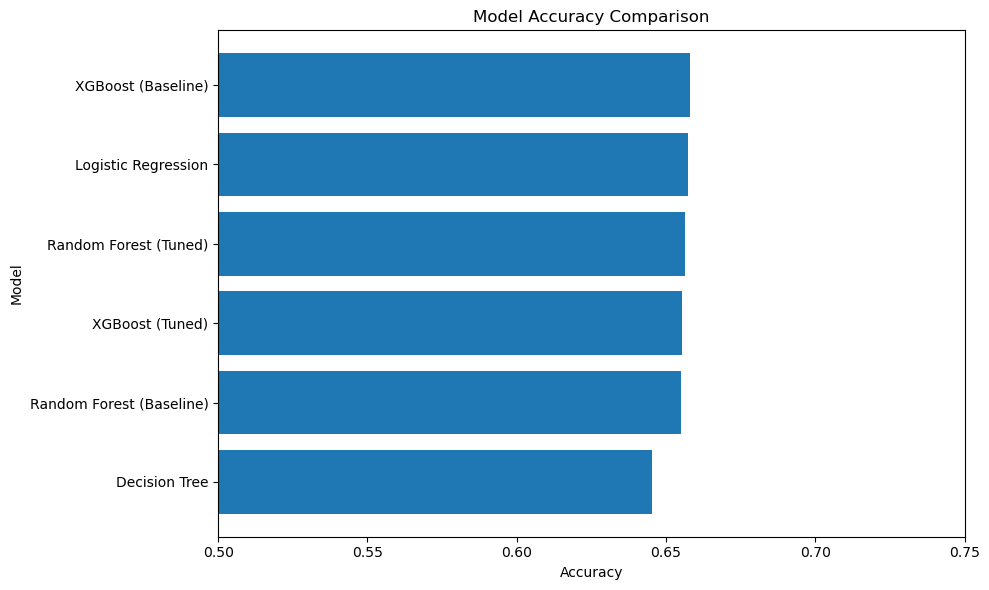

In [34]:
plot_df_acc = results.sort_values(by="Accuracy", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(plot_df_acc["Model"], plot_df_acc["Accuracy"])
plt.xlim(0.5, 0.75)   
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.title("Model Accuracy Comparison")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

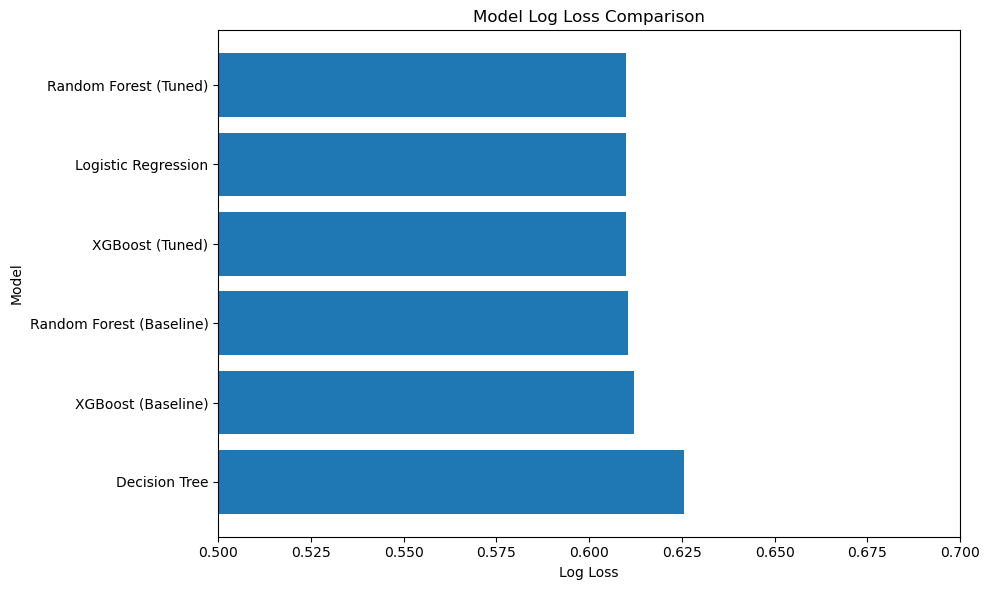

In [35]:
plot_df_ll = results.sort_values(by="LogLoss", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(plot_df_ll["Model"], plot_df_ll["LogLoss"])
plt.xlim(0.5, 0.7)   
plt.xlabel("Log Loss")
plt.ylabel("Model")
plt.title("Model Log Loss Comparison")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_logloss_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Global SHAP Importance

Global SHAP importance for XGBoost is presented first to show the overall explanatory pattern across the test set.

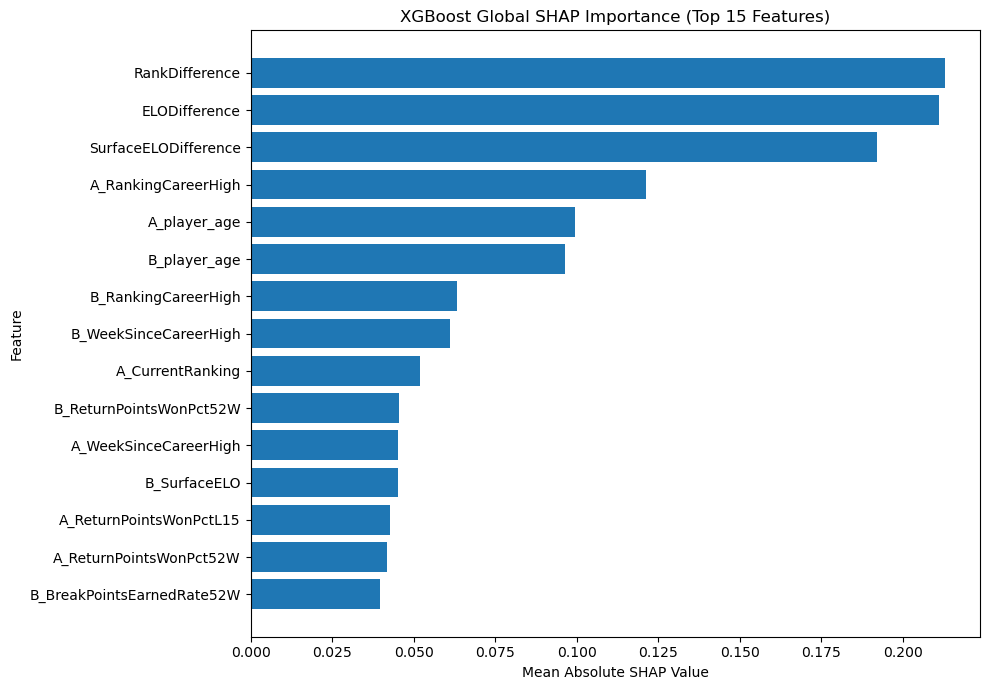

In [36]:
xgb_global_plot = xgb_global_importance.head(15).iloc[::-1]

plt.figure(figsize=(10, 7))
plt.barh(xgb_global_plot["Feature"], xgb_global_plot["Importance"])
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("XGBoost Global SHAP Importance (Top 15 Features)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "xgb_global_shap_top15.png", dpi=300, bbox_inches="tight")
plt.show()

In [37]:
xgb_global_importance.head(20)

,Feature,Importance
0,RankDifference,0.213029
1,ELODifference,0.211016
2,SurfaceELODifference,0.191972
3,A_RankingCareerHigh,0.121278
4,A_player_age,0.099576
5,B_player_age,0.096381
6,B_RankingCareerHigh,0.063367
7,B_WeekSinceCareerHigh,0.061220
8,A_CurrentRanking,0.051825
9,B_ReturnPointsWonPct52W,0.045354


## 5. Filtered Tennis-Specific Feature Importance Across Models

Broad strength indicators such as ranking and Elo dominate the global SHAP results. To focus more directly on tennis-specific performance indicators, the filtered feature-importance outputs are visualised here across Logistic Regression, Random Forest, and XGBoost.

In [38]:
top_n = 12

lr_plot = lr_global_filtered.head(top_n).iloc[::-1]
rf_plot = rf_global_filtered.head(top_n).iloc[::-1]
xgb_plot = xgb_global_filtered.head(top_n).iloc[::-1]

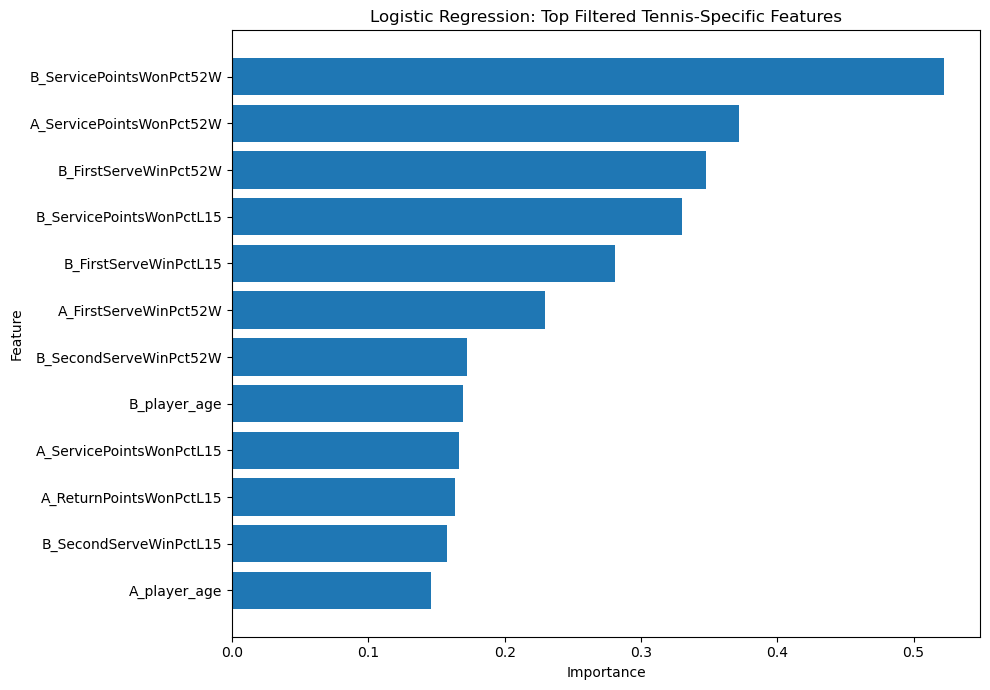

In [39]:
plt.figure(figsize=(10, 7))
plt.barh(lr_plot["Feature"], lr_plot["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Logistic Regression: Top Filtered Tennis-Specific Features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "lr_filtered_features.png", dpi=300, bbox_inches="tight")
plt.show()

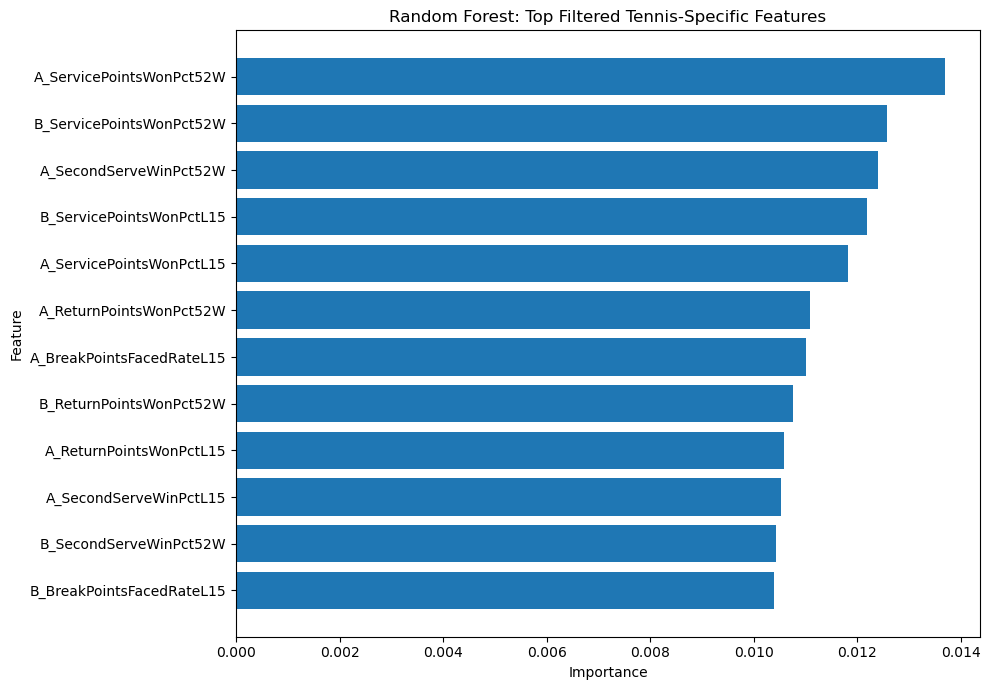

In [40]:
plt.figure(figsize=(10, 7))
plt.barh(rf_plot["Feature"], rf_plot["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest: Top Filtered Tennis-Specific Features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rf_filtered_features.png", dpi=300, bbox_inches="tight")
plt.show()

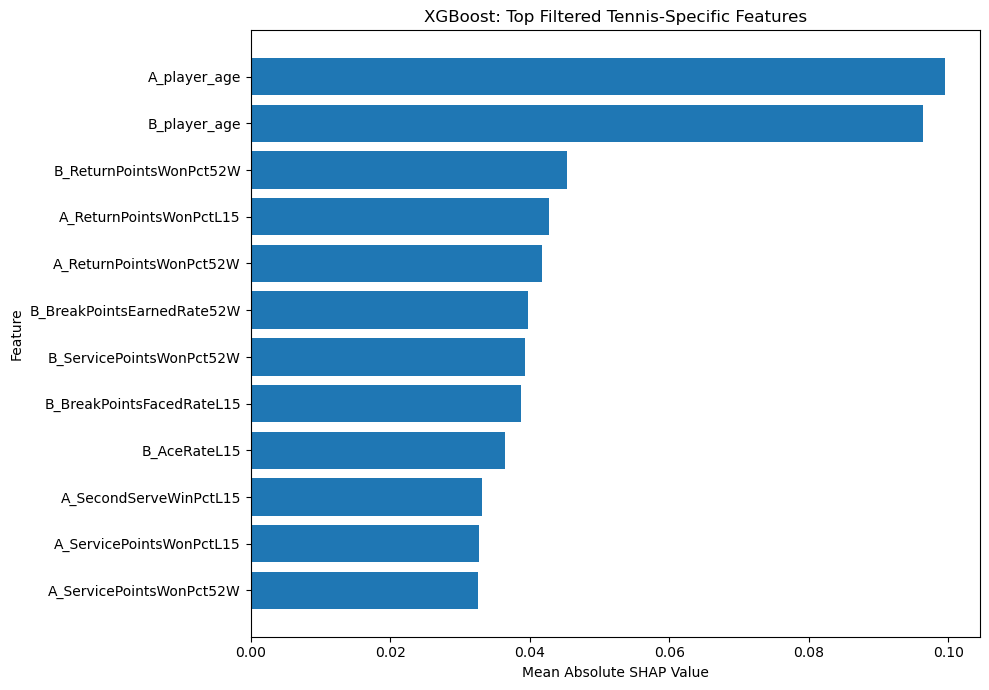

In [41]:
plt.figure(figsize=(10, 7))
plt.barh(xgb_plot["Feature"], xgb_plot["Importance"])
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("XGBoost: Top Filtered Tennis-Specific Features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "xgb_filtered_features.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Surface-Specific SHAP Importance

To investigate whether feature importance varies across playing conditions, SHAP importance is examined separately for grass and clay matches.

Filtered SHAP values are used to focus on tennis-specific performance indicators, excluding broad strength variables such as ranking and Elo.

In [42]:
# Select top features
top_n = 12

grass_plot = grass_filtered.head(top_n).iloc[::-1]
clay_plot = clay_filtered.head(top_n).iloc[::-1]

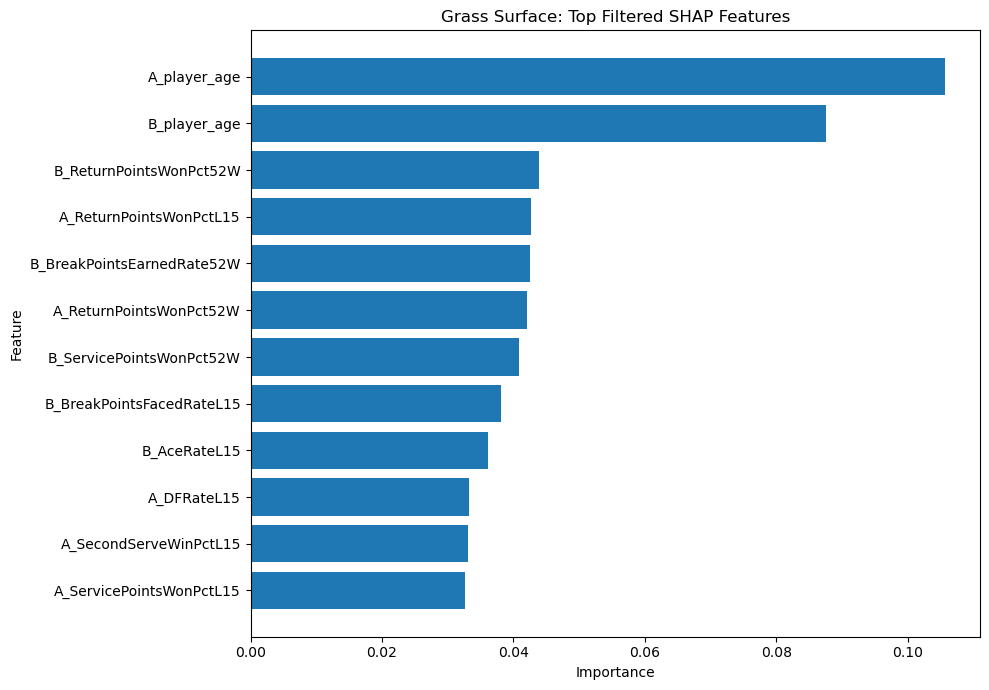

In [45]:
plt.figure(figsize=(10, 7))
plt.barh(grass_plot["Feature"], grass_plot["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Grass Surface: Top Filtered SHAP Features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "grass_filtered_features.png", dpi=300, bbox_inches="tight")
plt.show()

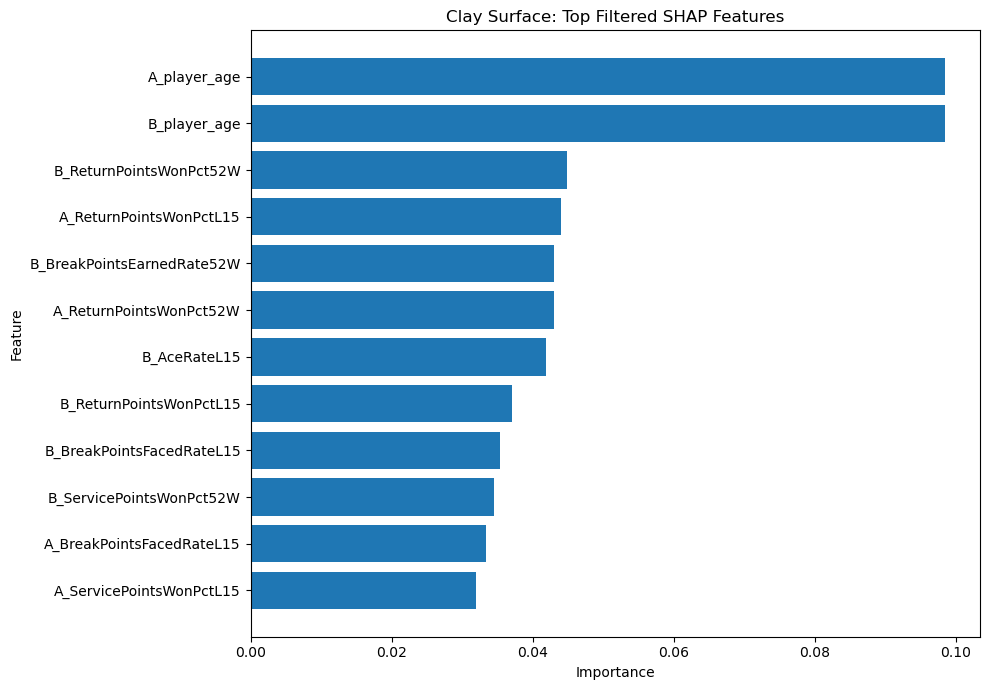

In [46]:
plt.figure(figsize=(10, 7))
plt.barh(clay_plot["Feature"], clay_plot["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Clay Surface: Top Filtered SHAP Features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "clay_filtered_features.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Surface-Relevant Tennis Feature Comparison

To investigate whether feature importance varies across playing conditions, filtered feature importance is examined with a focus on tennis-specific performance indicators, such as serve and return statistics.

Although SHAP-based surface analysis was initially conducted using XGBoost, the resulting outputs did not provide a sufficiently clear separation of tennis-related patterns for interpretation. Instead, the dominance of broader model signals limited the ability to meaningfully compare surface-specific behaviour.

For this reason, the surface-level comparison focuses on the filtered feature importance outputs from Logistic Regression and Random Forest. These models provide clearer visibility of tennis-specific variables and allow for more interpretable comparison of how serve- and return-related features contribute across matches.

This section therefore examines how tennis performance indicators are represented across models, rather than relying solely on a single model’s SHAP outputs.

## 6.1 Model-Based Tennis Feature Comparison

The filtered feature importance outputs from Logistic Regression and Random Forest are presented below. These highlight the most influential tennis-specific performance indicators within each model.

By examining these outputs, differences in how models represent tennis-related information can be observed, particularly in relation to serve and return performance metrics.

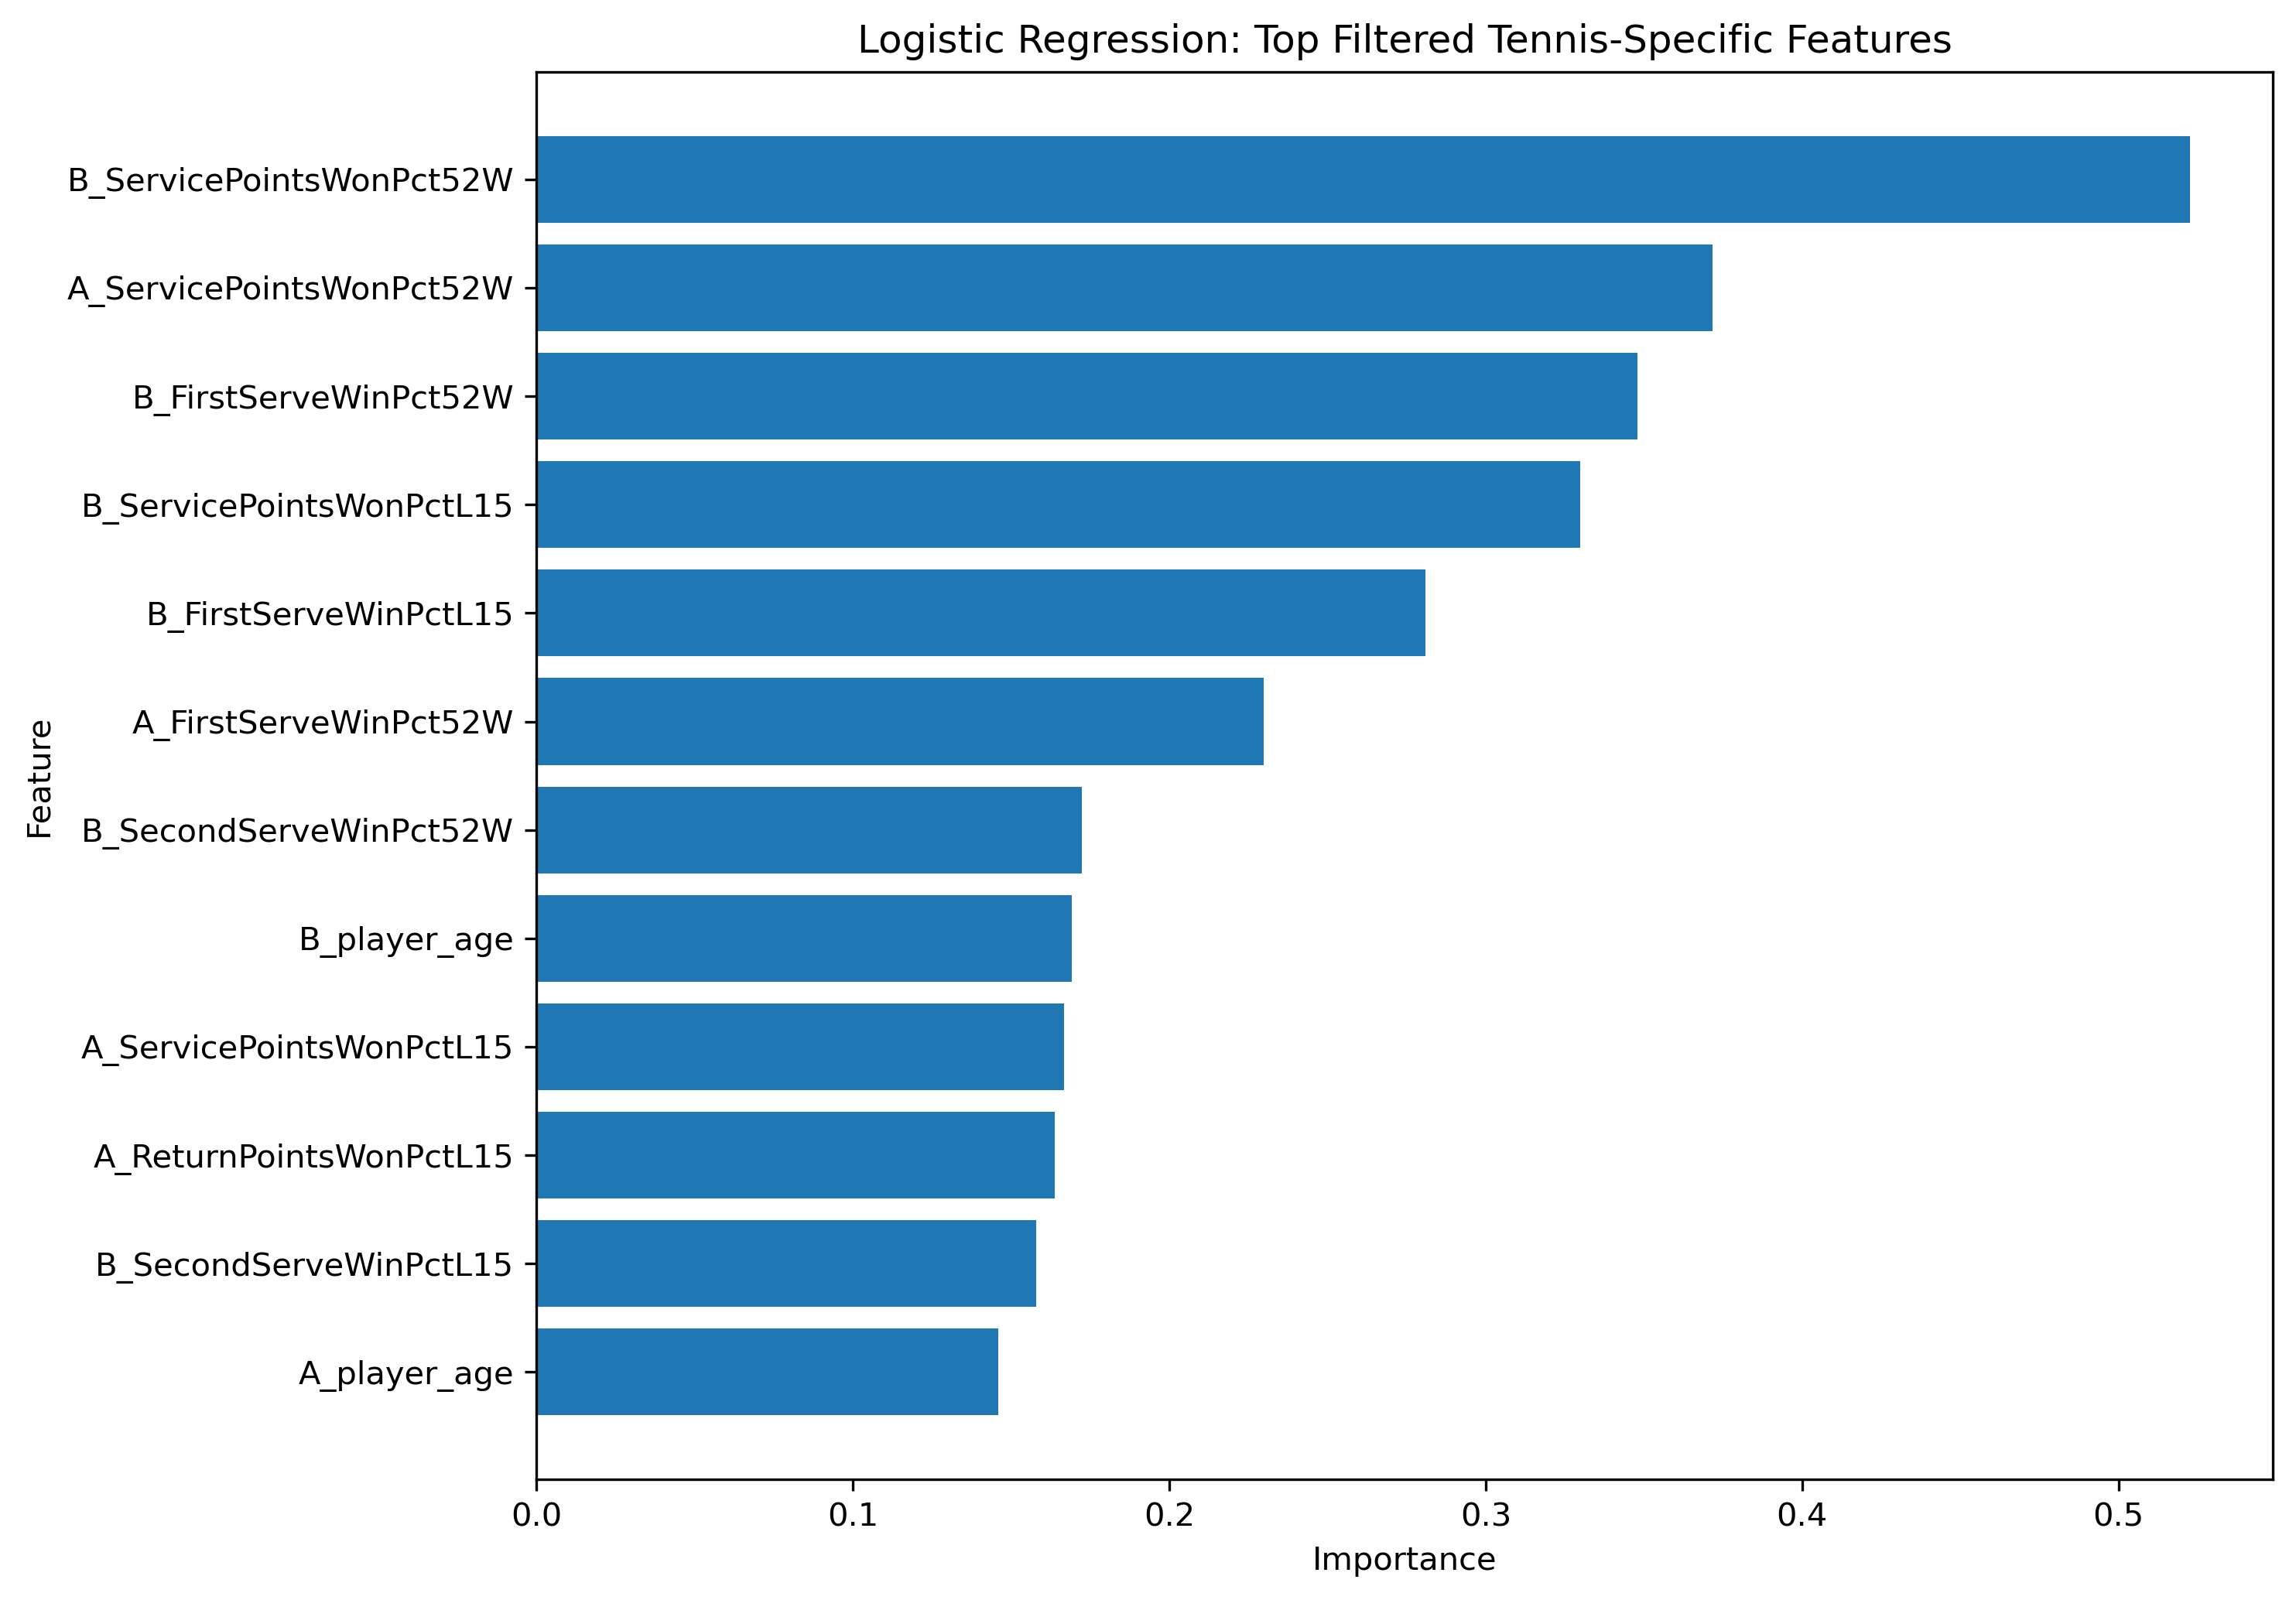

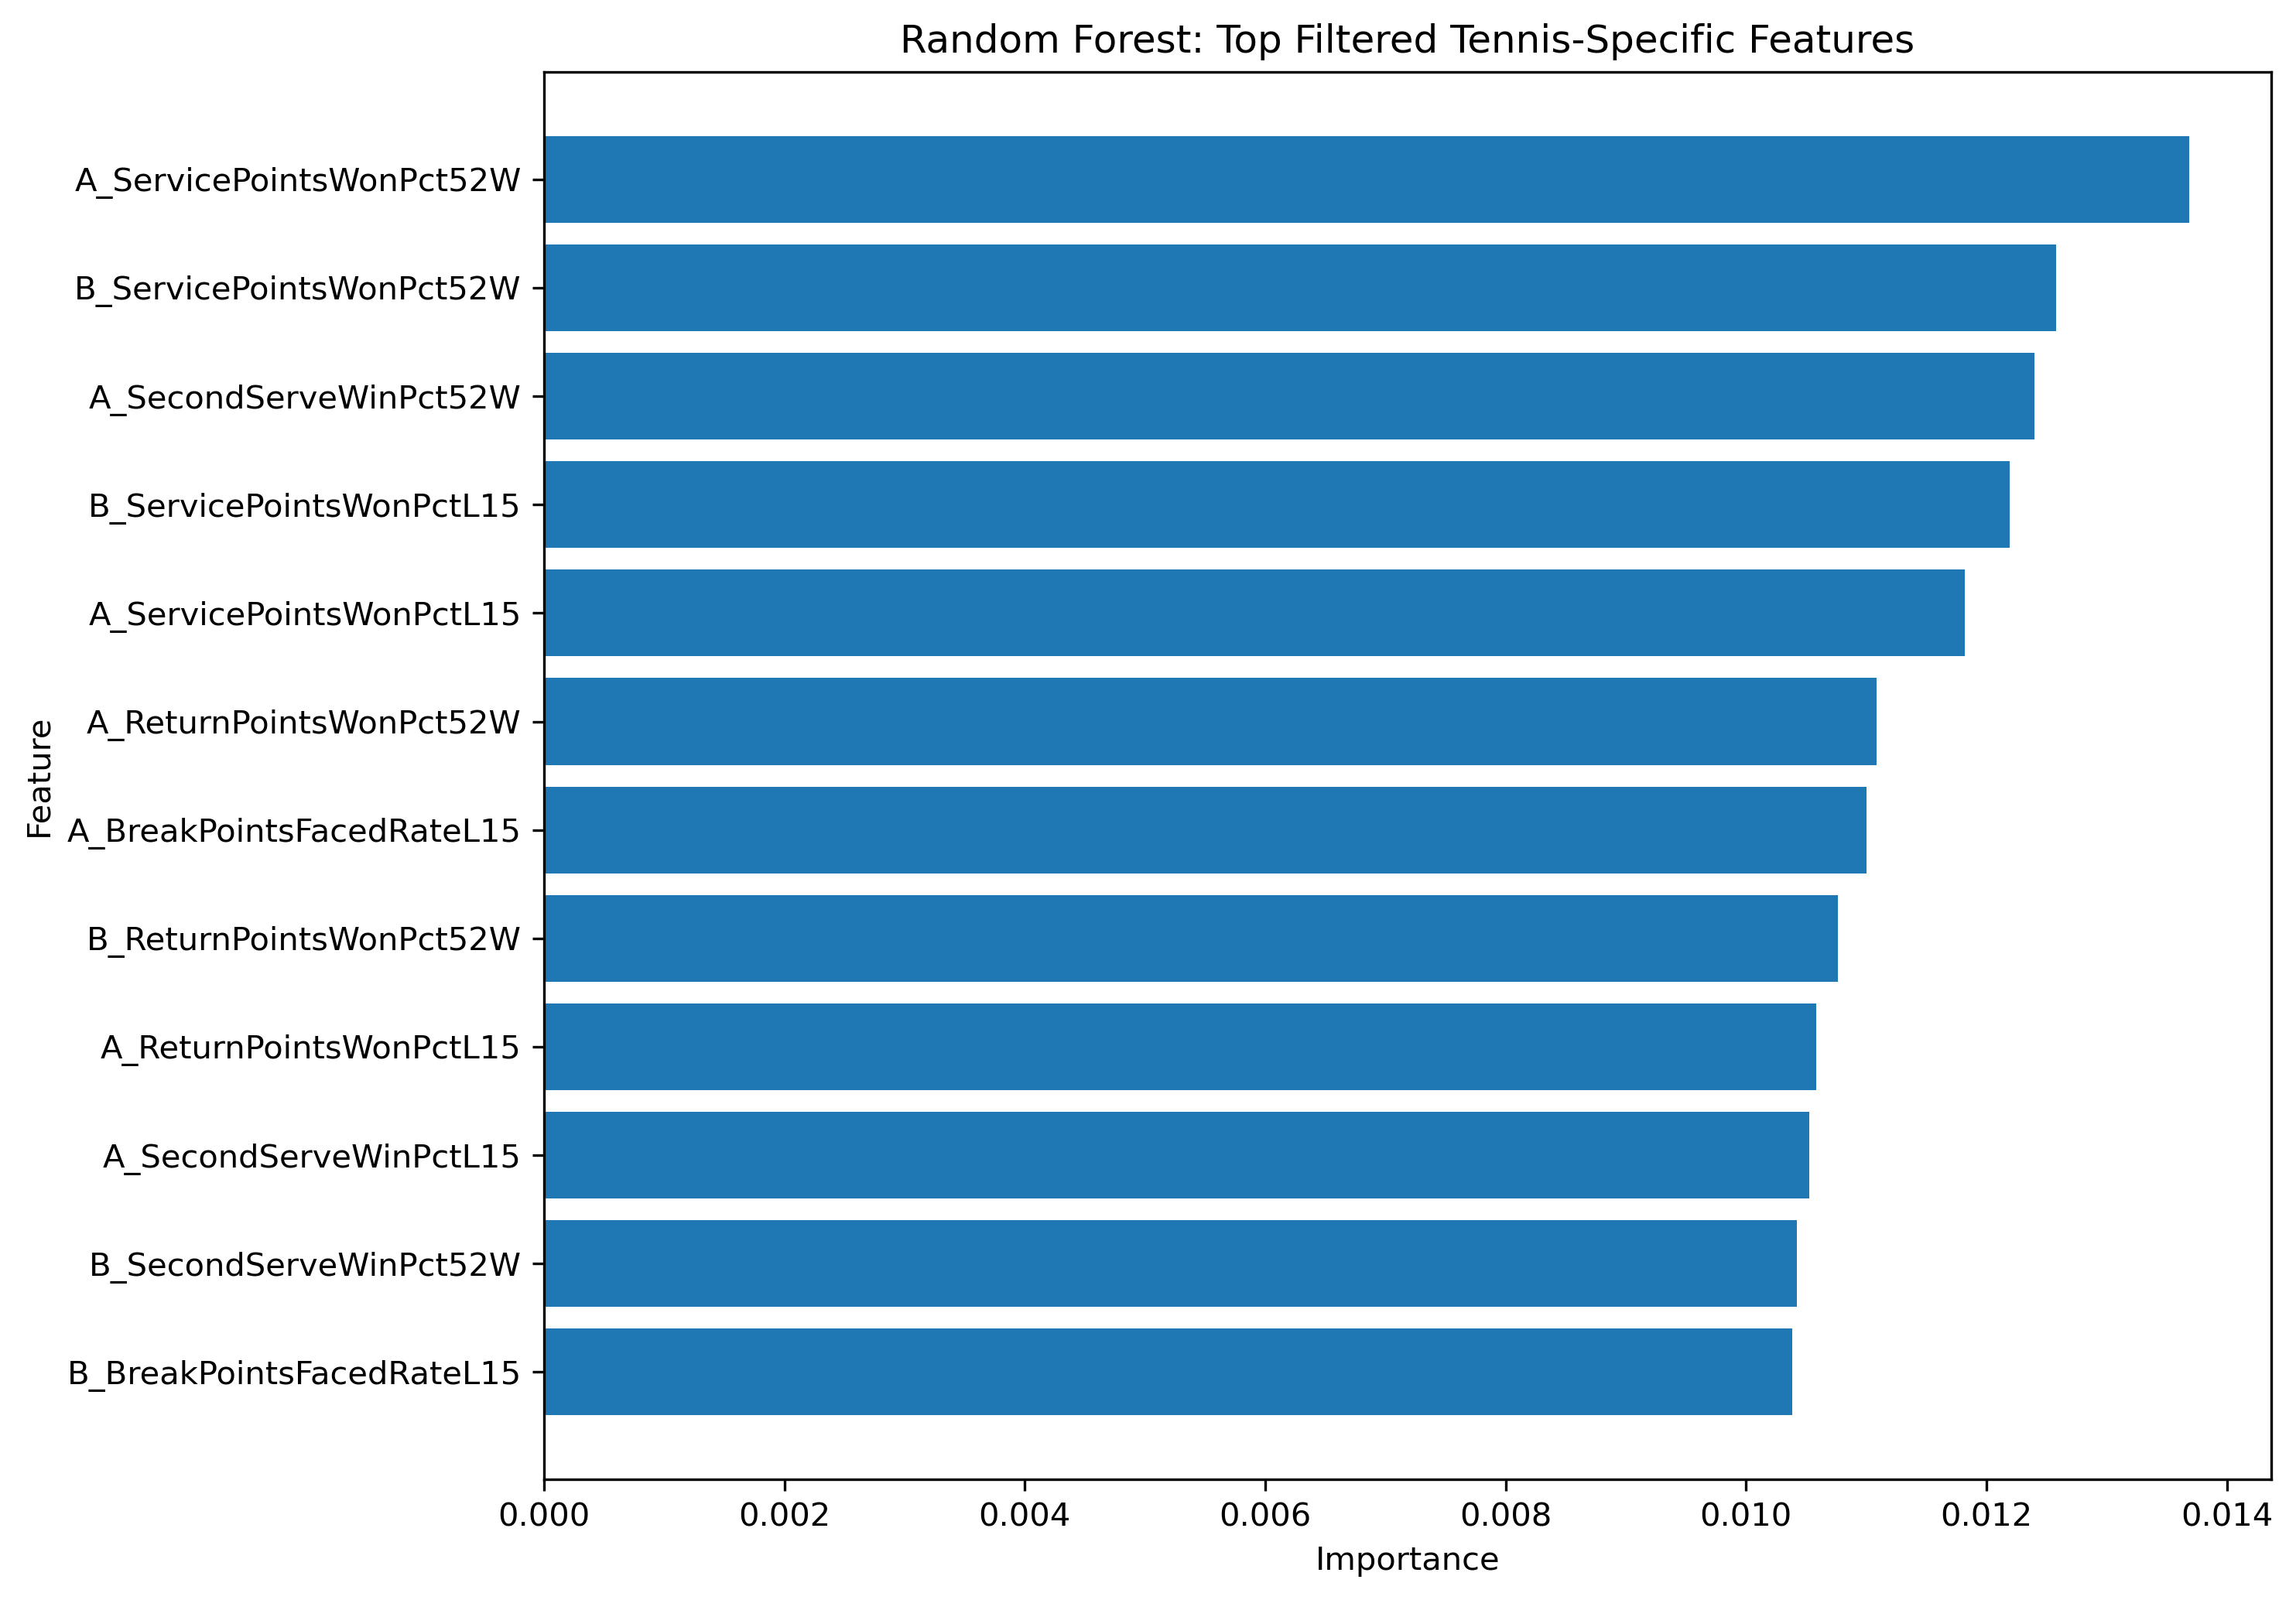

In [51]:
from IPython.display import Image, display

display(Image(filename=OUTPUT_DIR / "lr_filtered_features.png", width=750))
display(Image(filename=OUTPUT_DIR / "rf_filtered_features.png", width=750))

## 6.2 Surface-Specific Feature Comparison

To further examine the role of context in tennis match prediction, filtered feature importance is analysed separately for grass and clay matches using Logistic Regression and Random Forest.

By isolating matches by surface, this comparison provides insight into whether different types of tennis performance indicators are emphasised under different playing conditions. In particular, the analysis focuses on serve-related and return-related variables, which are expected to vary in importance depending on surface characteristics.

The resulting plots allow for comparison of how each model represents tennis-specific features across surfaces. Logistic Regression provides a clearer ranking of dominant features, while Random Forest distributes importance more evenly across multiple variables. This enables a structured comparison of how serve performance, return effectiveness, and pressure-related metrics contribute differently across grass and clay contexts.

This surface-specific analysis complements the earlier model-based comparison by introducing contextual variation, and supports the broader aim of identifying how interpretable models can reveal meaningful patterns in tennis performance beyond general strength indicators.

In [53]:
lr_surface_filtered = pd.read_csv(OUTPUT_DIR / "lr_surface_filtered.csv")
rf_grass_filtered = pd.read_csv(OUTPUT_DIR / "rf_grass_filtered.csv")
rf_clay_filtered = pd.read_csv(OUTPUT_DIR / "rf_clay_filtered.csv")

print("Loaded surface comparison files")

Loaded surface comparison files


In [54]:
print("Logistic Regression surface-supporting filtered features")
display(lr_surface_filtered.head(12))

print("Random Forest grass filtered features")
display(rf_grass_filtered.head(12))

print("Random Forest clay filtered features")
display(rf_clay_filtered.head(12))

Logistic Regression surface-supporting filtered features


,Feature,Importance
0,B_ServicePointsWonPct52W,0.522665
1,A_ServicePointsWonPct52W,0.371648
2,B_FirstServeWinPct52W,0.347992
3,B_ServicePointsWonPctL15,0.329871
4,B_FirstServeWinPctL15,0.281018
5,A_FirstServeWinPct52W,0.229788
6,B_SecondServeWinPct52W,0.172337
7,B_player_age,0.169049
8,A_ServicePointsWonPctL15,0.166805
9,A_ReturnPointsWonPctL15,0.163788


Random Forest grass filtered features


,Feature,Importance
0,B_ServicePointsWonPct52W,0.007642
1,B_ServicePointsWonPctL15,0.005203
2,A_FirstServeWinPct52W,0.004553
3,B_AceRateL15,0.004065
4,A_ServicePointsWonPct52W,0.003902
5,B_FirstServeWinPct52W,0.003740
6,B_player_ht,0.003740
7,B_BreakPointsSavedPctL15,0.003740
8,A_SecondServeWinPct52W,0.003577
9,A_FirstServeWinPctL15,0.003577


Random Forest clay filtered features


,Feature,Importance
0,B_FirstServeInPctL15,0.001694
1,A_BreakPointsConvertedPct52W,0.001694
2,B_BreakPointsEarnedRateL15,0.001317
3,A_SecondServeWinPctL15,0.001255
4,A_SecondServeWinPct52W,0.001255
5,B_BreakPointsEarnedRate52W,0.001066
6,B_ReturnPointsWonPct52W,0.001066
7,A_player_age,0.000941
8,A_ServicePointsWonPctL15,0.000690
9,B_ReturnPointsWonPctL15,0.000565


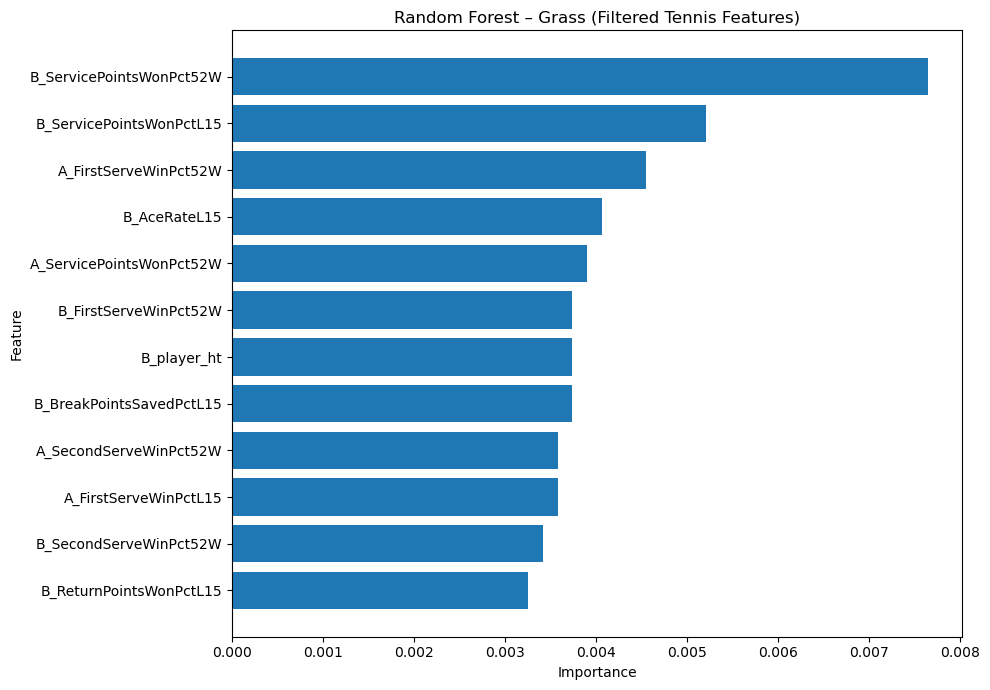

In [55]:
rf_grass_plot = rf_grass_filtered.head(12).iloc[::-1]

plt.figure(figsize=(10, 7))
plt.barh(rf_grass_plot["Feature"], rf_grass_plot["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest – Grass (Filtered Tennis Features)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rf_grass_filtered.png", dpi=300, bbox_inches="tight")
plt.show()

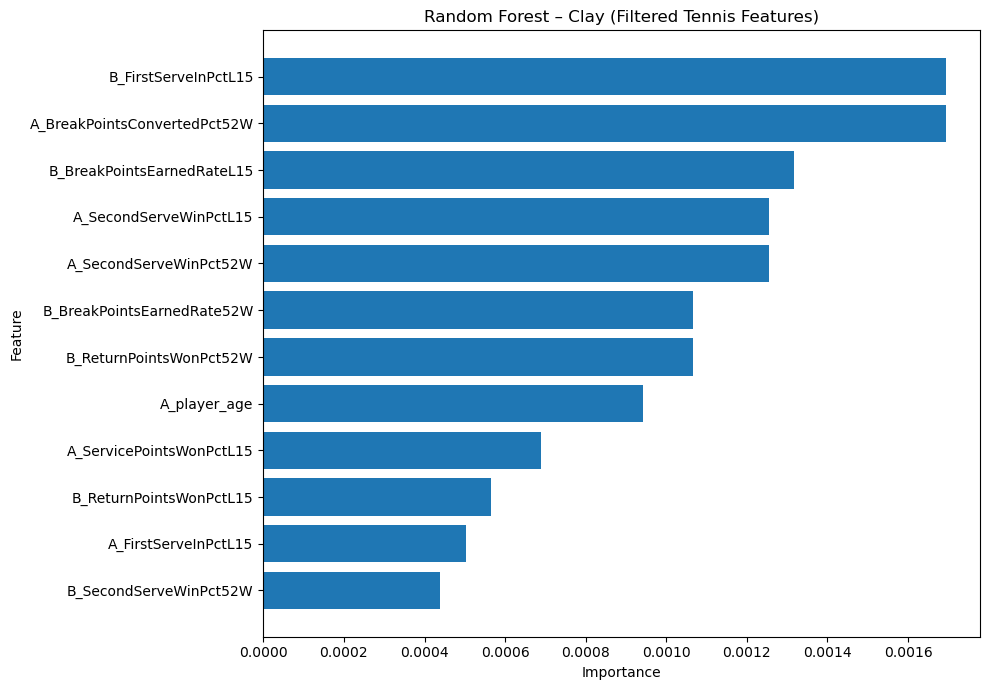

In [56]:
rf_clay_plot = rf_clay_filtered.head(12).iloc[::-1]

plt.figure(figsize=(10, 7))
plt.barh(rf_clay_plot["Feature"], rf_clay_plot["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest – Clay (Filtered Tennis Features)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rf_clay_filtered.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Local SHAP Case Study Visualisations

This section presents three match-level case studies using SHAP explanations from the XGBoost model.

These examples illustrate how local explanations can reveal match-specific predictive drivers beyond general strength indicators. Each case represents a different tennis context, including surface variation, ranking differences, and competitive balance.

The aim is to demonstrate how interpretability methods provide insight into individual predictions, supporting the broader goal of understanding model behaviour in real-world tennis scenarios.

### 7.1 Case Study: Raonic vs Kecmanovic (Grass)

This match represents a grass-court scenario with a large ranking difference. It is used to examine how the model balances strong baseline indicators with surface-specific performance features.

In [57]:
display(case_raonic_meta)
display(case_raonic_shap.head(15))

,tourney_date,A_surface,A_player_name,B_player_name,A_CurrentRanking,B_CurrentRanking,RankDifference,A_ELO,B_ELO,ELODifference,A_SurfaceELO,B_SurfaceELO,SurfaceELODifference,pred_prob_A_win,actual_A_win
0,2023-06-12,Grass,Milos Raonic,Miomir Kecmanovic,738.0,39.0,699.0,1778.467304,1616.606372,161.860932,1736.293574,1530.377685,205.915889,0.552808,1


,Feature,FeatureValue,SHAPValue,AbsSHAP
0,RankDifference,699.000000,-0.582332,0.582332
1,SurfaceELODifference,205.915889,0.431713,0.431713
2,ELODifference,161.860932,0.263157,0.263157
3,A_RankingCareerHigh,3.000000,0.194643,0.194643
4,A_BreakPointsConvertedPct52W,0.600000,-0.176021,0.176021
5,A_CurrentRanking,738.000000,-0.123650,0.123650
6,A_player_age,32.400000,-0.082821,0.082821
7,B_WeekSinceCareerHigh,21.000000,0.079031,0.079031
8,B_RankSTD52W,3.206212,-0.074108,0.074108
9,A_FirstServeInPct52W,0.573034,-0.072728,0.072728


### 7.2 Case Study: Norrie vs Etcheverry (Clay)

This case represents a clay-court match between similarly ranked players. It highlights how return performance and pressure-related statistics contribute to predictions in more balanced matchups.

In [58]:
display(case_norrie_meta)
display(case_norrie_shap.head(15))

,tourney_date,A_surface,A_player_name,B_player_name,A_CurrentRanking,B_CurrentRanking,RankDifference,A_ELO,B_ELO,ELODifference,A_SurfaceELO,B_SurfaceELO,SurfaceELODifference,pred_prob_A_win,actual_A_win
0,2024-04-15,Clay,Cameron Norrie,Tomas Martin Etcheverry,31.0,30.0,1.0,1690.427482,1648.864146,41.563336,1694.098713,1636.484242,57.614471,0.600946,0


,Feature,FeatureValue,SHAPValue,AbsSHAP
0,RankDifference,1.000000,-0.118714,0.118714
1,SurfaceELODifference,57.614471,0.115102,0.115102
2,A_RankingCareerHigh,8.000000,0.110429,0.110429
3,A_player_age,28.600000,0.092654,0.092654
4,B_WeekSinceCareerHigh,7.000000,0.079775,0.079775
5,A_ReturnPointsWonPctL15,0.414229,0.074851,0.074851
6,B_DFRateL15,0.012066,0.059576,0.059576
7,A_SecondServeWinPctL15,0.526013,0.049058,0.049058
8,A_WeekSinceCareerHigh,80.000000,0.047714,0.047714
9,B_SurfaceELO,1636.484242,-0.046749,0.046749


### 7.3 Case Study: Sinner vs Alcaraz (Elite Match)

This case examines a high-level match between closely ranked players. It demonstrates how predictions can be influenced by a combination of multiple performance indicators rather than a single dominant factor.

In [59]:
display(case_sinner_meta)
display(case_sinner_shap.head(15))

,tourney_date,A_surface,A_player_name,B_player_name,A_CurrentRanking,B_CurrentRanking,RankDifference,A_ELO,B_ELO,ELODifference,A_SurfaceELO,B_SurfaceELO,SurfaceELODifference,pred_prob_A_win,actual_A_win
0,2024-03-04,Hard,Jannik Sinner,Carlos Alcaraz,3.0,2.0,1.0,2142.003316,2017.449217,124.5541,2121.091761,1947.82895,173.262811,0.602213,0


,Feature,FeatureValue,SHAPValue,AbsSHAP
0,SurfaceELODifference,173.262811,0.397208,0.397208
1,ELODifference,124.554100,0.205209,0.205209
2,RankDifference,1.000000,-0.190674,0.190674
3,A_RankingCareerHigh,3.000000,0.187169,0.187169
4,B_player_age,20.800000,-0.184119,0.184119
5,B_ReturnPointsWonPct52W,0.422318,-0.171177,0.171177
6,B_RankingCareerHigh,1.000000,-0.161088,0.161088
7,A_player_age,22.500000,0.139478,0.139478
8,A_CurrentRanking,3.000000,0.138012,0.138012
9,B_ServicePointsWonPct52W,0.680895,-0.119392,0.119392


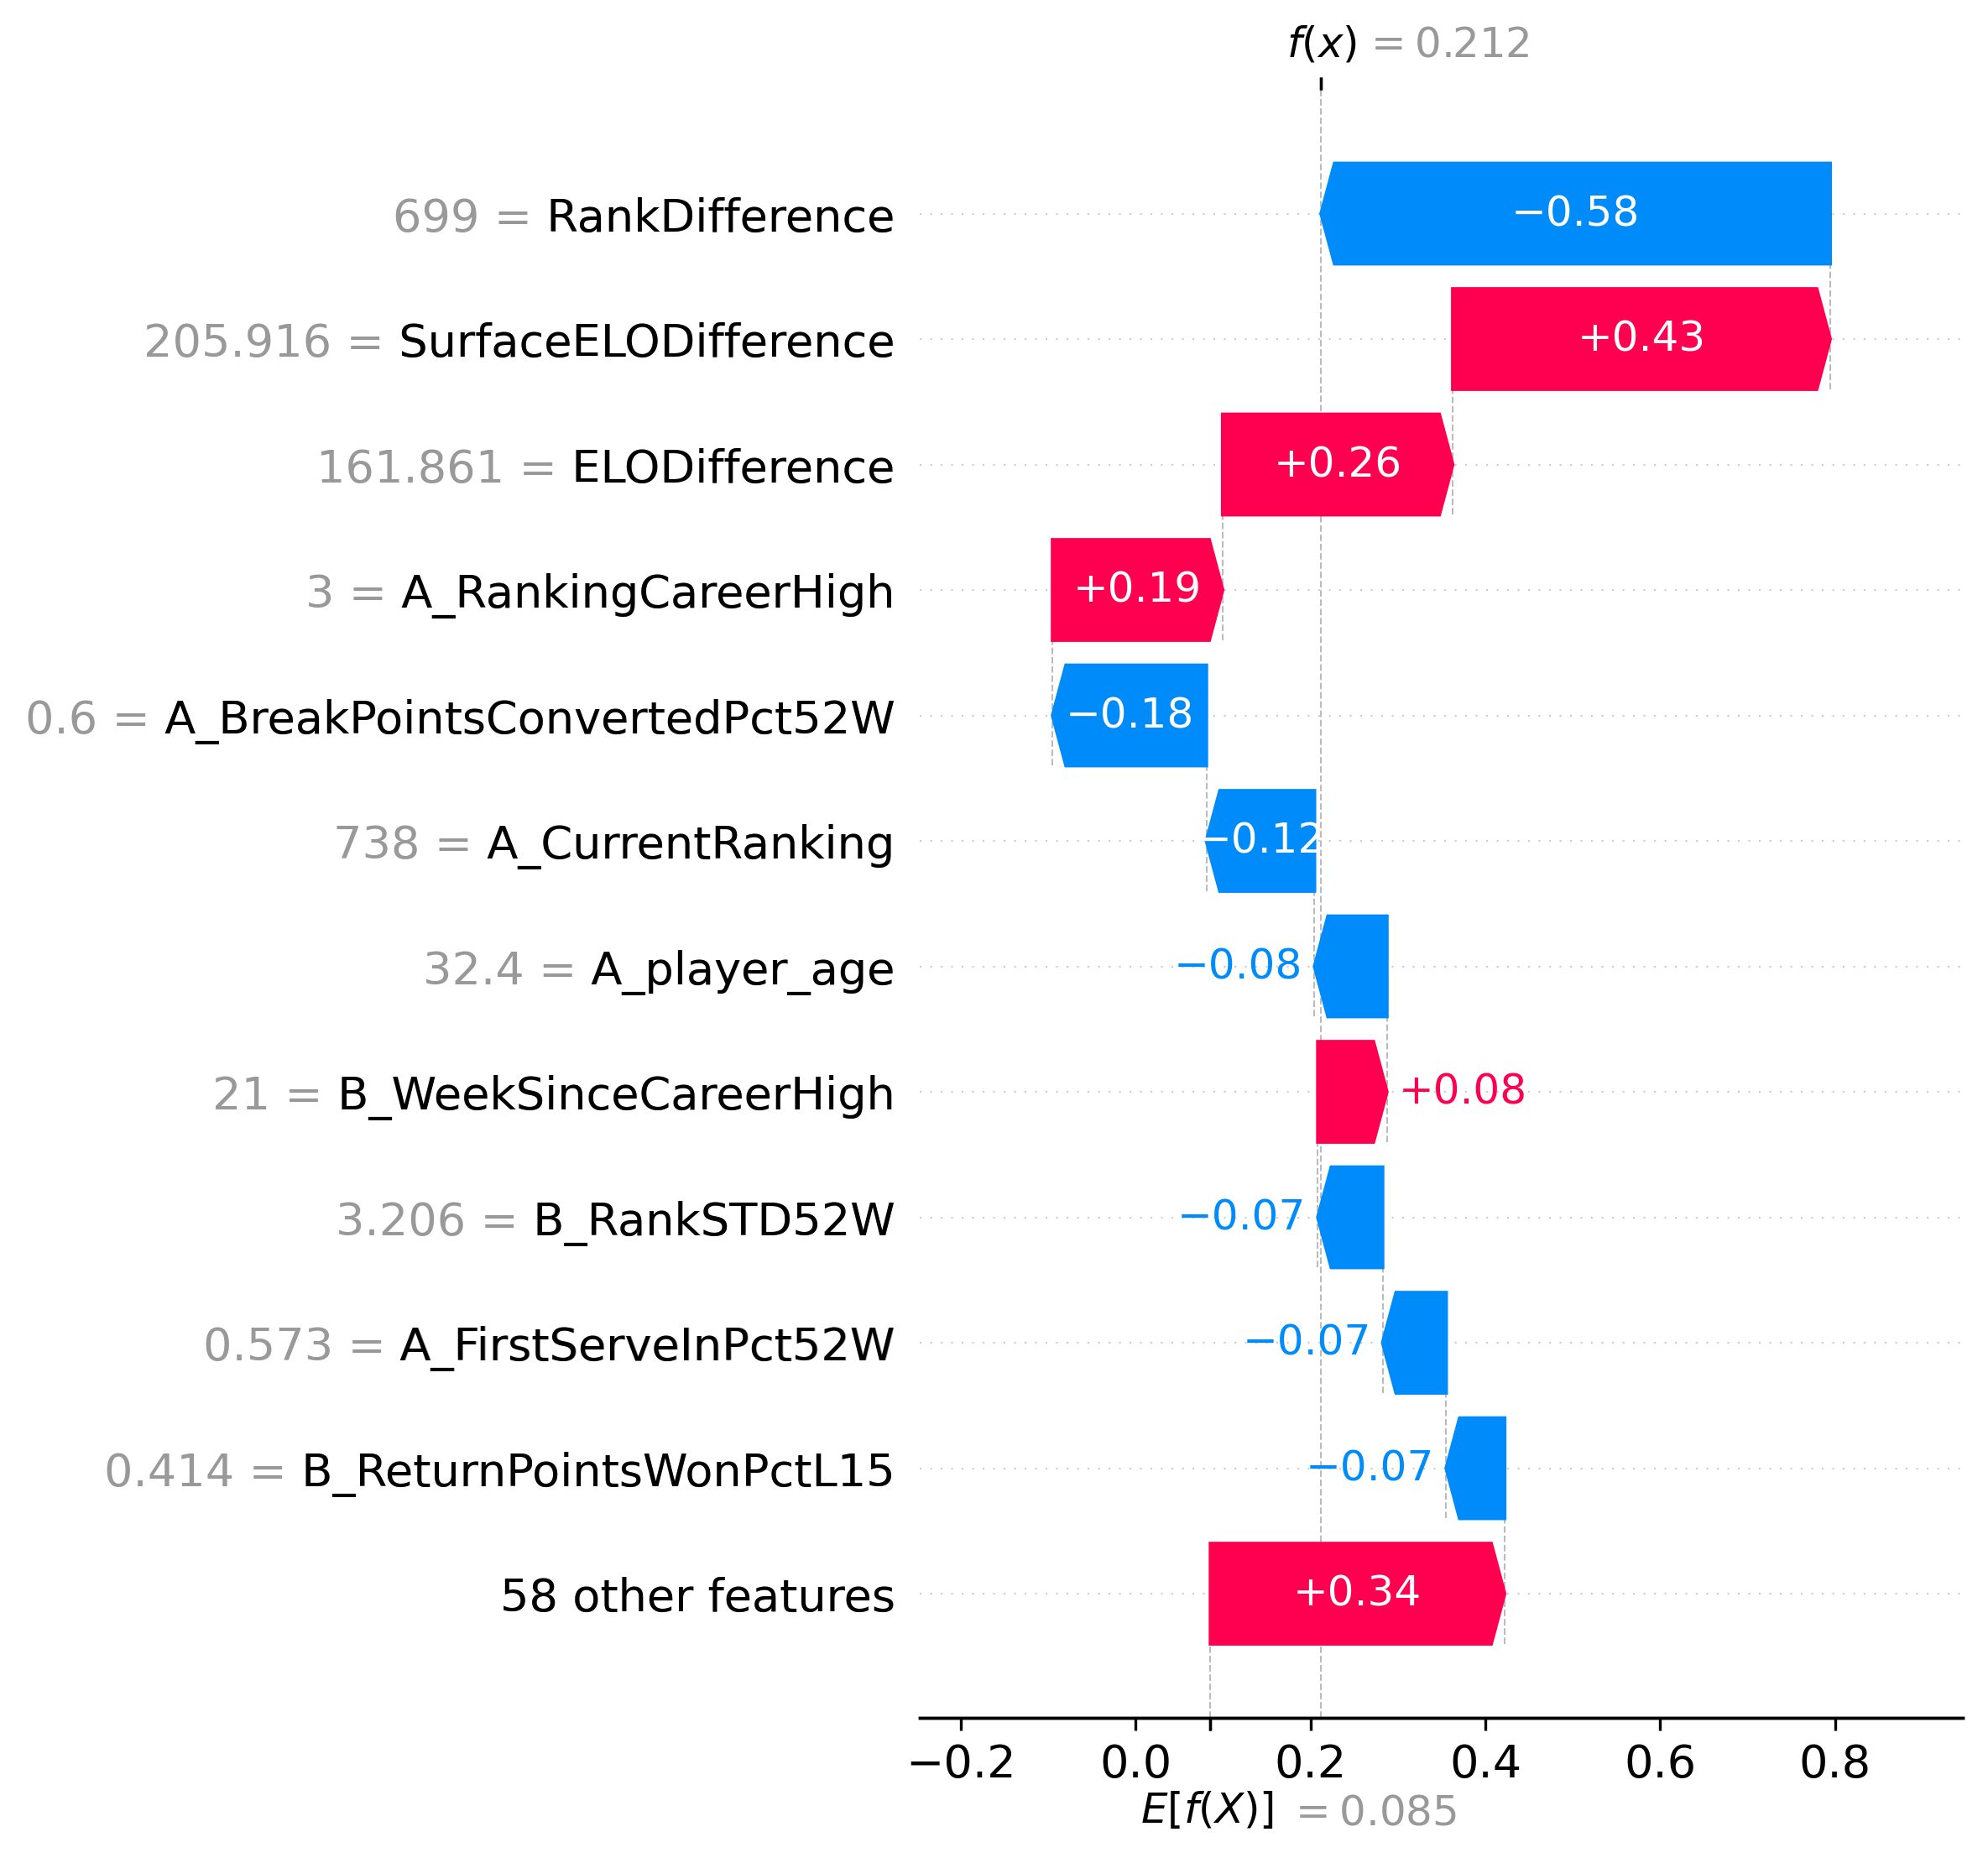

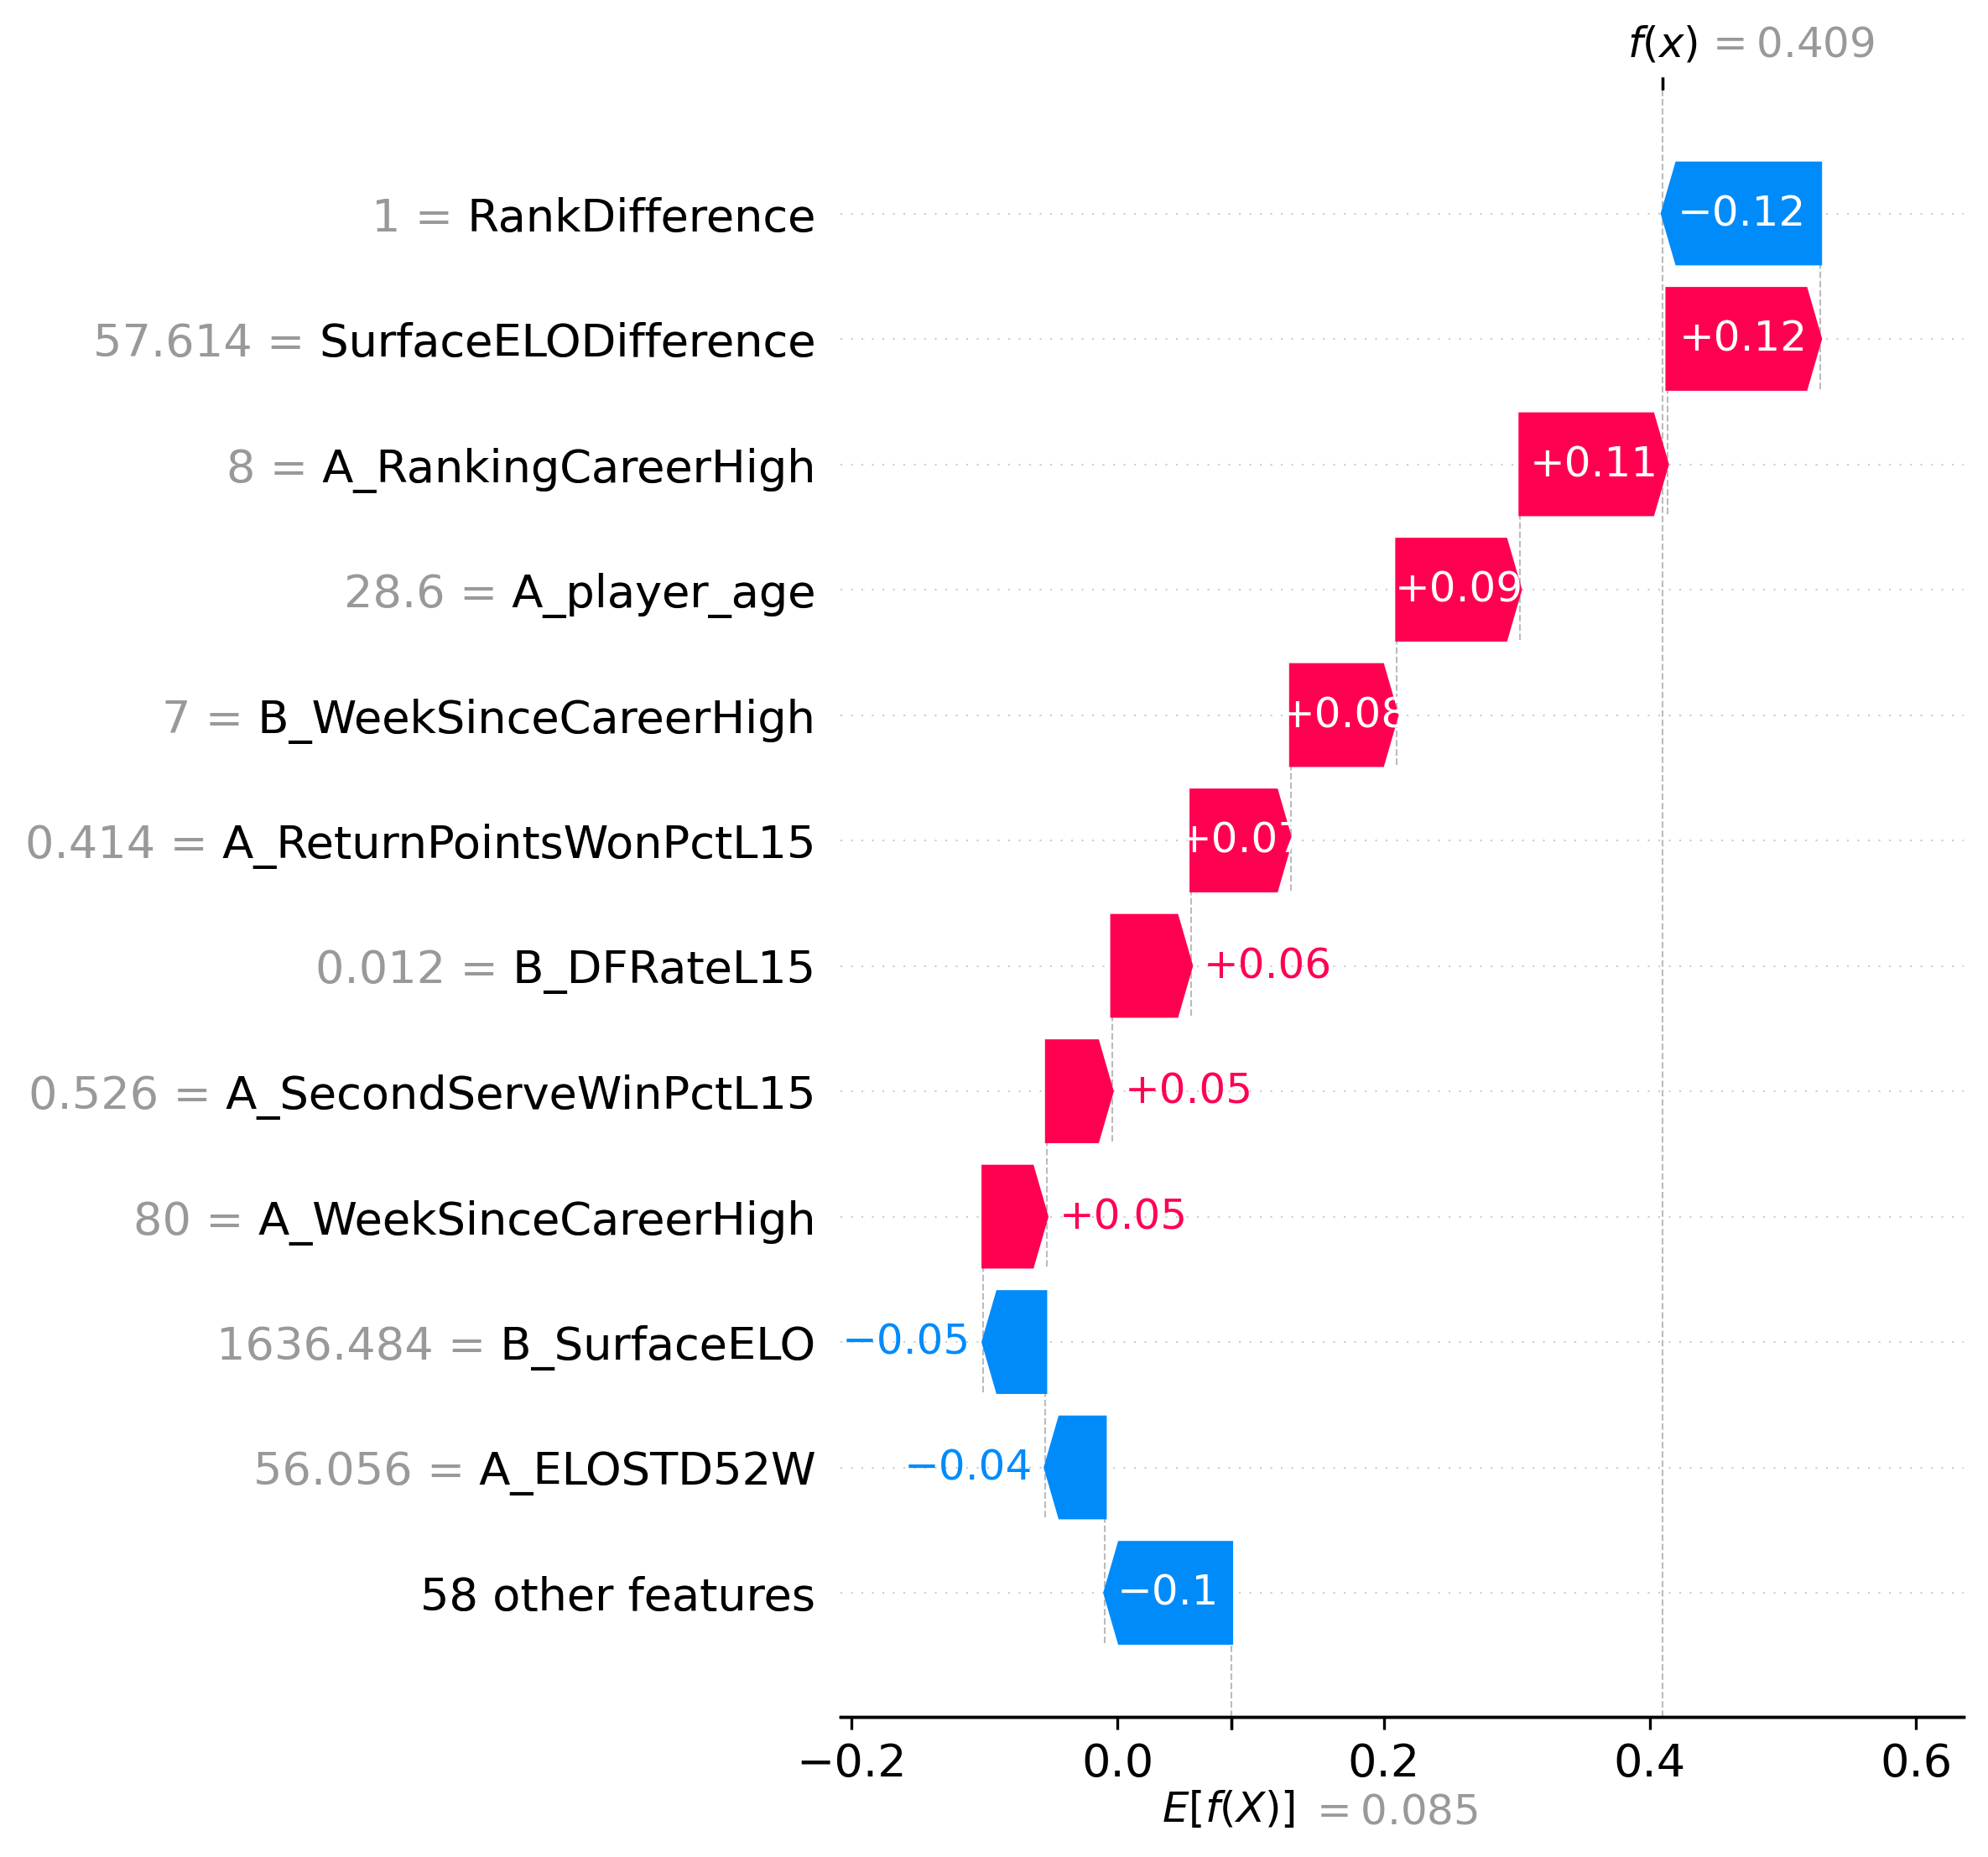

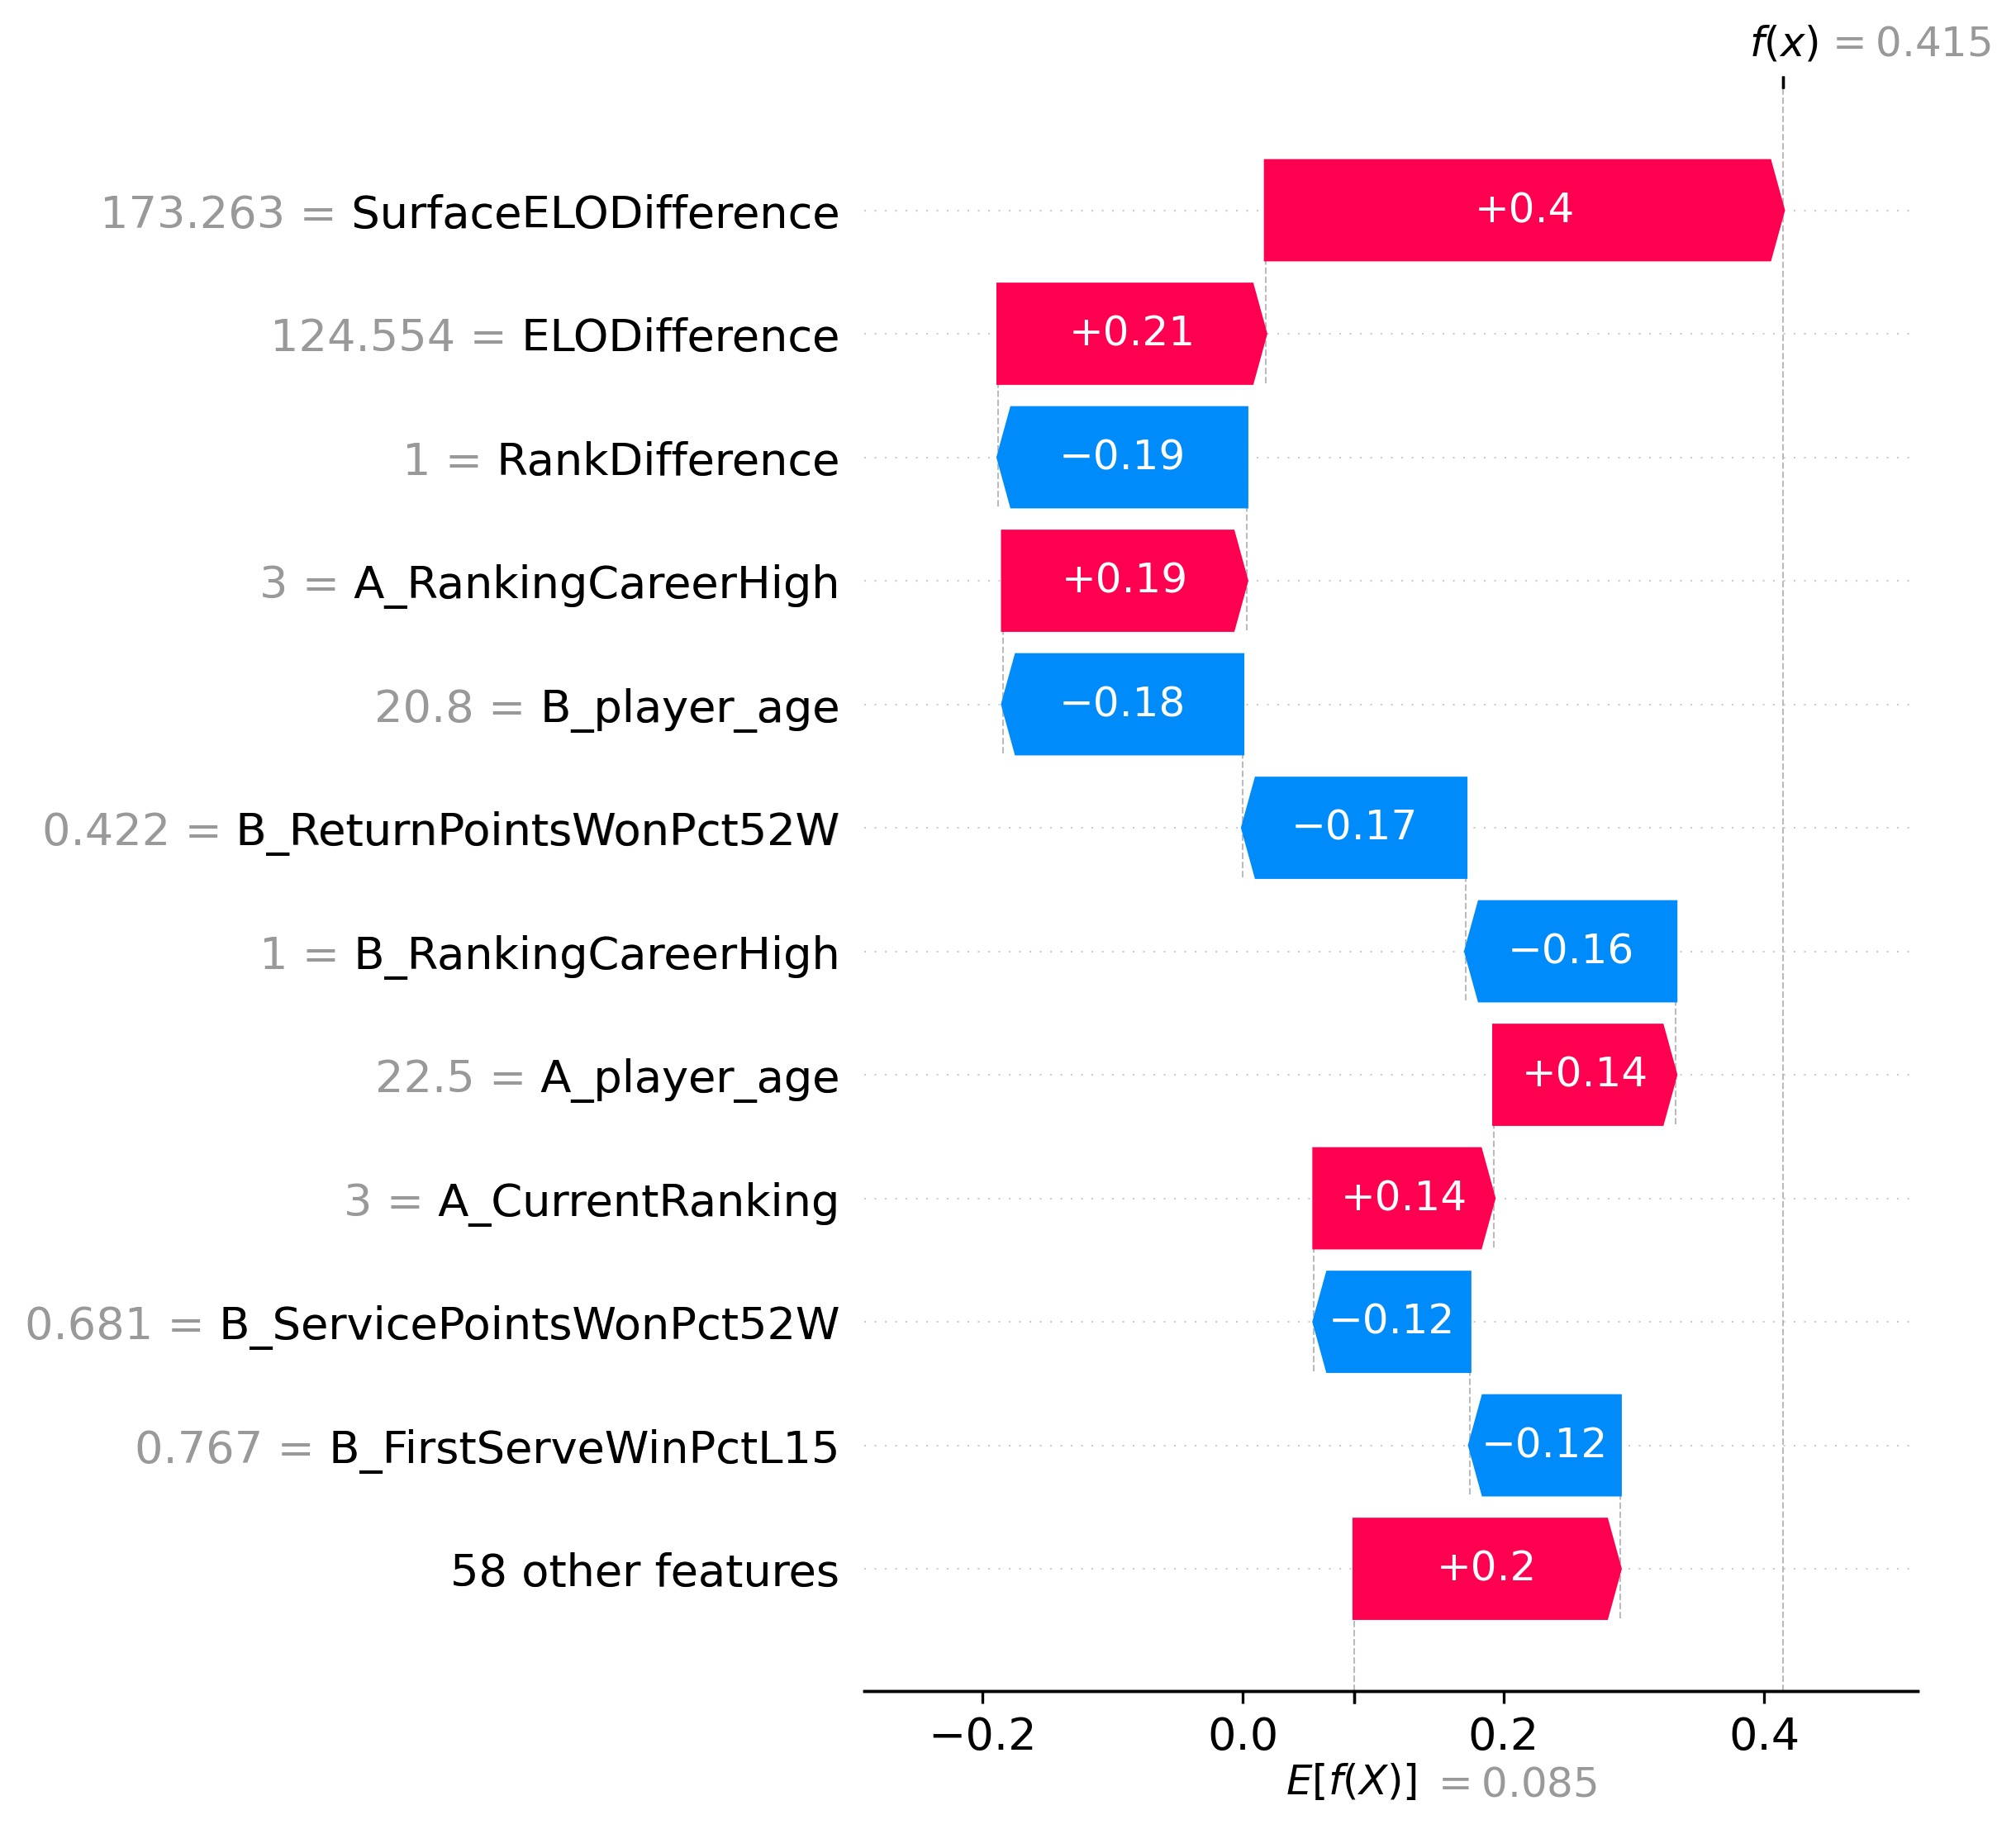

In [60]:
from IPython.display import Image, display

display(Image(filename=OUTPUT_DIR / "raonic_waterfall.png", width=700))
display(Image(filename=OUTPUT_DIR / "norrie_waterfall.png", width=700))
display(Image(filename=OUTPUT_DIR / "sinner_waterfall.png", width=700))